In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from kepler_utils import *

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

In [3]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

### Comparison Nguyen et al. (2020)

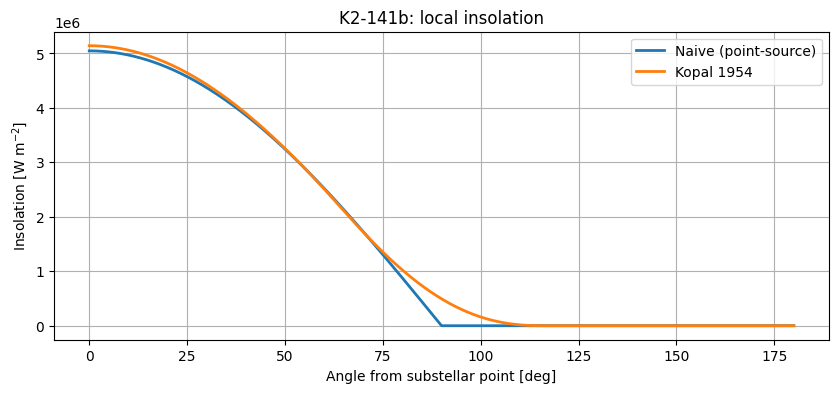

In [4]:
theta = np.linspace(0, 180, 1000)  # angle from substellar point [deg]
insol_naive = naive_insolation(np.radians(theta), K2_141b)
insol_kopal = insolation_kopal(np.radians(theta), K2_141b)

plt.figure(figsize=(10, 4))
plt.plot(theta, insol_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, insol_kopal, linewidth=2, label="Kopal 1954")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title("K2-141b: local insolation")
plt.legend()
plt.grid()

/tmp/ipykernel_32762/2324155165.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


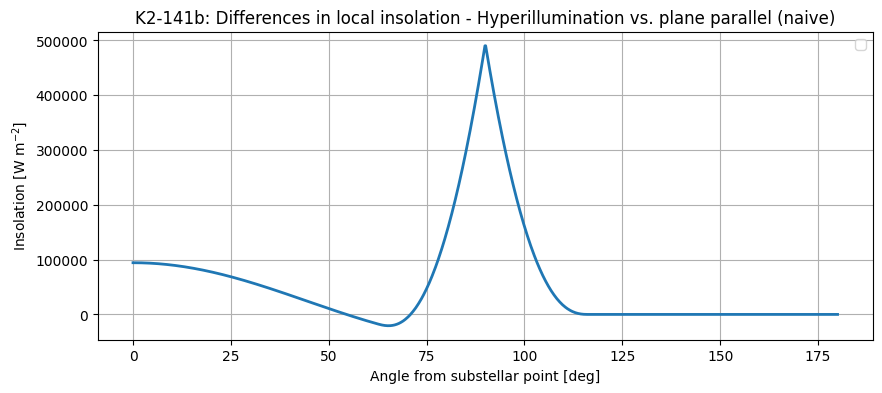

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(theta, insol_kopal-insol_naive, linewidth=2)
plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title("K2-141b: Differences in local insolation - Hyperillumination vs. plane parallel (naive)")
plt.legend()
plt.grid()
plt.show()

Luger 2022 & Carter 2024 predict that hyper-illumination models predict a hotter substellar point than the plane-parallel approximation.

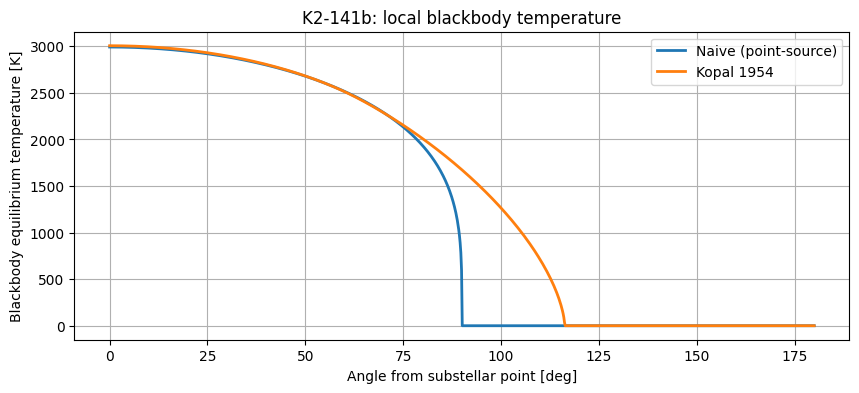

In [6]:
temp_naive = BBtemp_from_insolation(insol_naive)
temp_kopal = BBtemp_from_insolation(insol_kopal)

plt.figure(figsize=(10, 4))
plt.plot(theta, temp_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, temp_kopal, linewidth=2, label="Kopal 1954")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Blackbody equilibrium temperature [K]")
plt.title("K2-141b: local blackbody temperature")
plt.legend()
plt.grid()  

Temperature at 90° is around 1750K. The local BB spectrum peaks at around 1650nm. 
MIRI: 4.9 to 28.8 microns.

insolation_penumbra_mask runtime: 0.7872 s
insolation_penumbra_kopal runtime: 0.0012 s
insolation_penumbra_kopal_simpleint runtime: 0.4708 s
insolation_penumbra_kopal_approx runtime: 0.0001 s


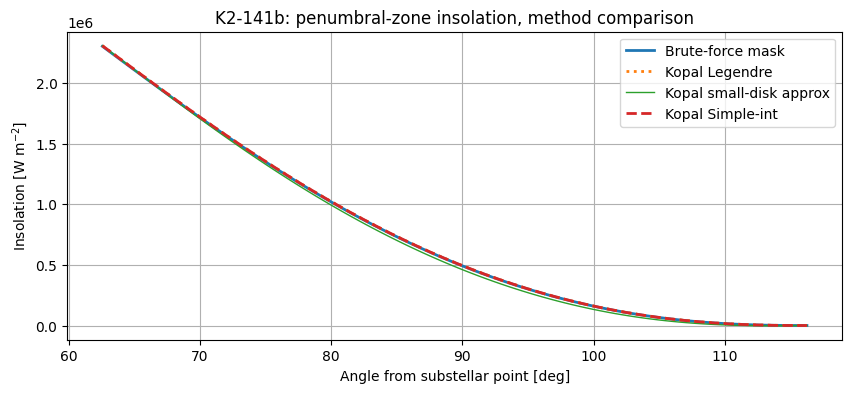

In [7]:
theta_pen = np.linspace(K2_141b.terminator_penumbra(unit="deg"), K2_141b.terminator_nightside(unit="deg"), 100)

insol_mask = insolation_penumbra_mask(np.radians(theta_pen), K2_141b, runtime=True)
insol_kopal_legendre = insolation_penumbra_kopal(np.radians(theta_pen), K2_141b, runtime=True)
insol_kopal_simpleint = insolation_penumbra_kopal_simpleint(np.radians(theta_pen), K2_141b, runtime=True)
insol_kopal_approx = insolation_penumbra_kopal_approx(np.radians(theta_pen), K2_141b, runtime=True)

plt.figure(figsize=(10, 4))
plt.plot(theta_pen, insol_mask, linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, insol_kopal_legendre, linewidth=2, linestyle=":", label="Kopal Legendre")
plt.plot(theta_pen, insol_kopal_approx, linewidth=1, label="Kopal small-disk approx")
plt.plot(theta_pen, insol_kopal_simpleint, linewidth=2, linestyle="--", label="Kopal Simple-int")


plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title("K2-141b: penumbral-zone insolation, method comparison")
plt.legend()
plt.grid()

/tmp/ipykernel_32762/3842758061.py:2: RuntimeWarning: invalid value encountered in divide
  plt.plot(theta_pen, np.abs(1-insol_mask/insol_kopal_simpleint), linewidth=2, label="Brute-force mask")
/tmp/ipykernel_32762/3842758061.py:3: RuntimeWarning: invalid value encountered in divide
  plt.plot(theta_pen, np.abs(1-insol_kopal_legendre/insol_kopal_simpleint), linewidth=2, linestyle=":", label="Kopal Legendre")


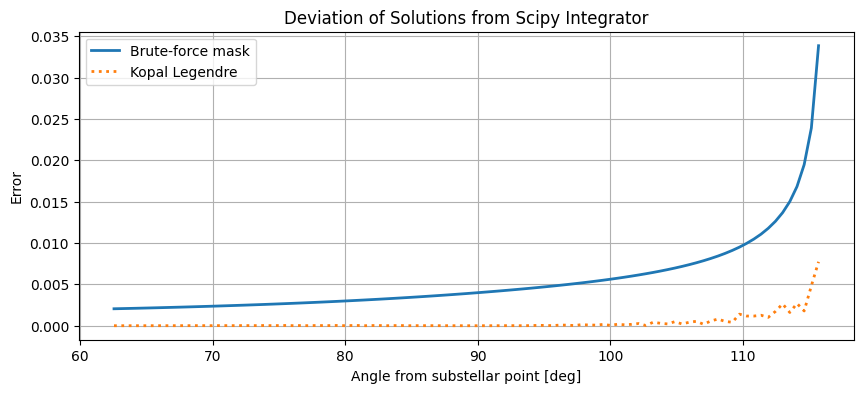

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(theta_pen, np.abs(1-insol_mask/insol_kopal_simpleint), linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, np.abs(1-insol_kopal_legendre/insol_kopal_simpleint), linewidth=2, linestyle=":", label="Kopal Legendre")
#plt.plot(theta_pen, np.abs(1-insol_kopal_approx/insol_kopal_simpleint), linewidth=1, label="Kopal small-disk approx")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Error")
plt.title("Deviation of Solutions from Scipy Integrator")
plt.legend()
plt.grid()

### Illuminated Fractions of Exoplanet

In [9]:
K2_141b.fraction_illuminated("extra")

{'fully illuminated': 0.2695122129072618, 'penumbra': 0.45175967677918105}

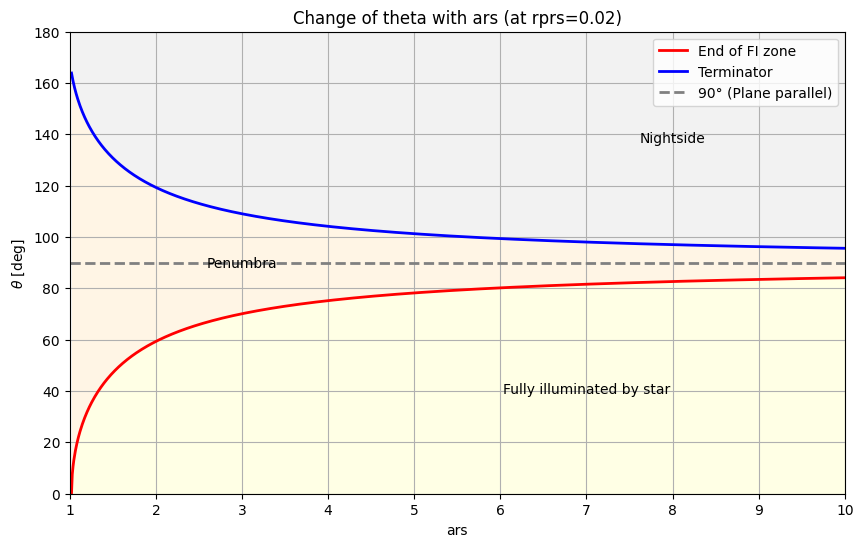

In [10]:
rprs=0.02 # r1/r2
ars=np.linspace(1+rprs,10, 1000) # R/r2
theta_inner = np.degrees(np.arccos((rprs+1)/ars))
theta_outer = np.degrees(np.arccos((rprs-1)/ars))

plt.figure(figsize=(10, 6))
plt.fill_between(ars, 0, theta_inner, color="yellow", alpha=0.1, linewidth=0, zorder=0)
plt.fill_between(ars, theta_inner, theta_outer, color="orange", alpha=0.1, linewidth=0, zorder=0)
plt.fill_between(ars, theta_outer, 180, color="grey", alpha=0.1, linewidth=0, zorder=0)

plt.text(7, np.interp(7, ars, theta_inner)/2, "Fully illuminated by star", ha="center", va="center", fontsize=10)
plt.text(3, (np.interp(3, ars, theta_inner)+np.interp(3, ars, theta_outer))/2, "Penumbra", ha="center", va="center", fontsize=10)
plt.text(8, (np.interp(8, ars, theta_outer)+180)/2, "Nightside", ha="center", va="center", fontsize=10)

plt.plot(ars, theta_inner, label="End of FI zone", color="red", linewidth=2)
plt.plot(ars, theta_outer, label="Terminator", color="blue", linewidth=2)
plt.axhline(90, linestyle="--", color="grey", label="90° (Plane parallel)", linewidth=2)

plt.title("Change of theta with ars (at rprs=0.02)")
plt.ylabel(r"$\theta$ [deg]")
plt.xlabel("ars")
plt.xlim([1, 10])
plt.ylim([0, 180])
plt.legend()
plt.grid()
plt.show()

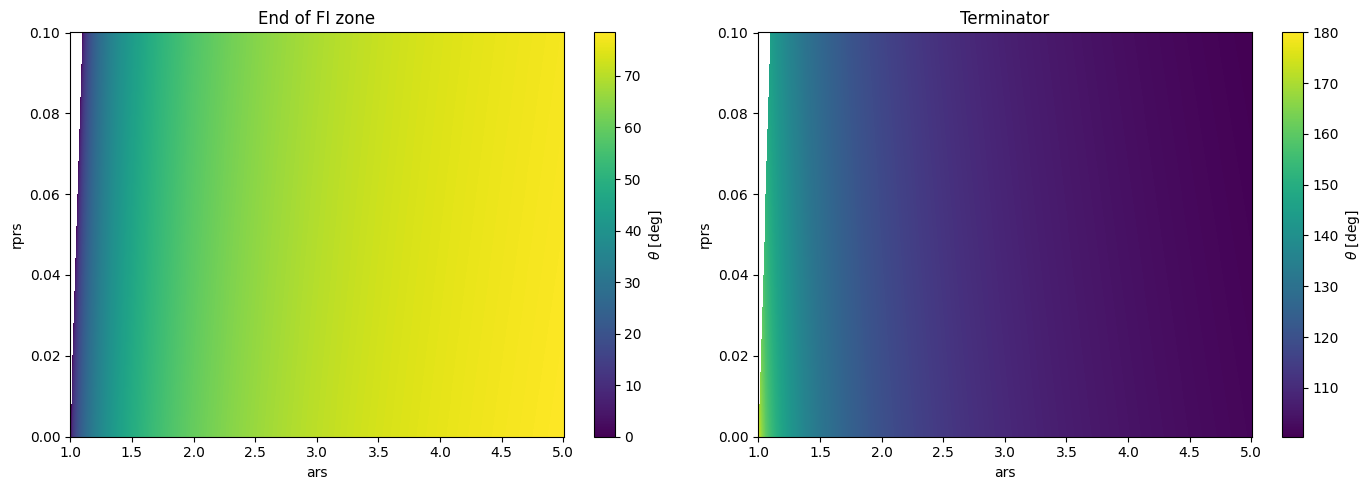

In [11]:
rprs_grid = np.linspace(0., 0.1, 1000)   # r1/r2
ars_grid = np.linspace(1., 5., 1000)    # R/r2
RPRS, ARS = np.meshgrid(rprs_grid, ars_grid, indexing="ij")

cos_inner = (RPRS + 1) / ARS
cos_outer = (RPRS - 1) / ARS

theta_inner_grid = np.where(np.abs(cos_inner) <= 1., np.degrees(np.arccos(np.clip(cos_inner, -1., 1.))), np.nan)
theta_outer_grid = np.where(np.abs(cos_inner) <= 1., np.degrees(np.arccos(np.clip(cos_outer, -1., 1.))), np.nan)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

im0 = axs[0].pcolormesh(ars_grid, rprs_grid, theta_inner_grid, shading="auto", cmap="viridis")
axs[0].set_title("End of FI zone")
axs[0].set_xlabel("ars")
axs[0].set_ylabel("rprs")
fig.colorbar(im0, ax=axs[0], label=r"$\theta$ [deg]")

im1 = axs[1].pcolormesh(ars_grid, rprs_grid, theta_outer_grid, shading="auto", cmap="viridis")
axs[1].set_title("Terminator")
axs[1].set_xlabel("ars")
axs[1].set_ylabel("rprs")
fig.colorbar(im1, ax=axs[1], label=r"$\theta$ [deg]")

plt.tight_layout()
plt.show()

### Planetary Insolation-/Heatmaps

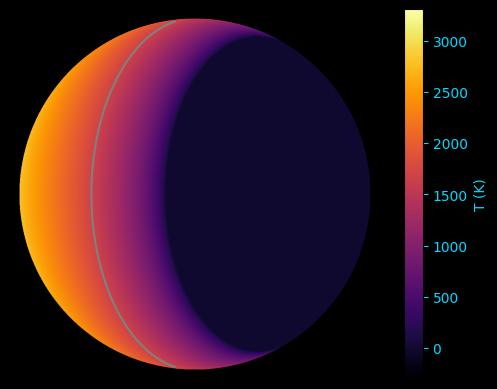

In [12]:
phase = 0.35
ax=plot_insolmap(phase, K2_141b, insolation_model="kopal", terminator=True, unit="temperature")

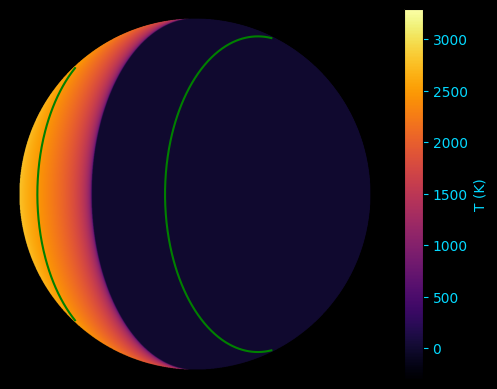

In [13]:
phase = 0.35
ax=plot_insolmap(phase, K2_141b, insolation_model="naive", show_penumbra="both", unit="temperature")

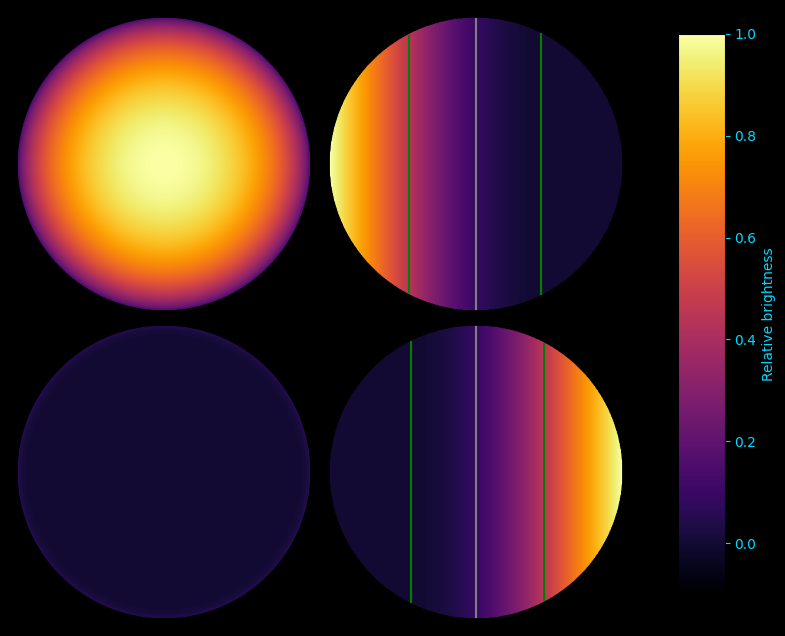

In [14]:
ax=plot_quad_insolmap(K2_141b, insolation_model="kopal", terminator=True, show_penumbra="both", unit="flux")

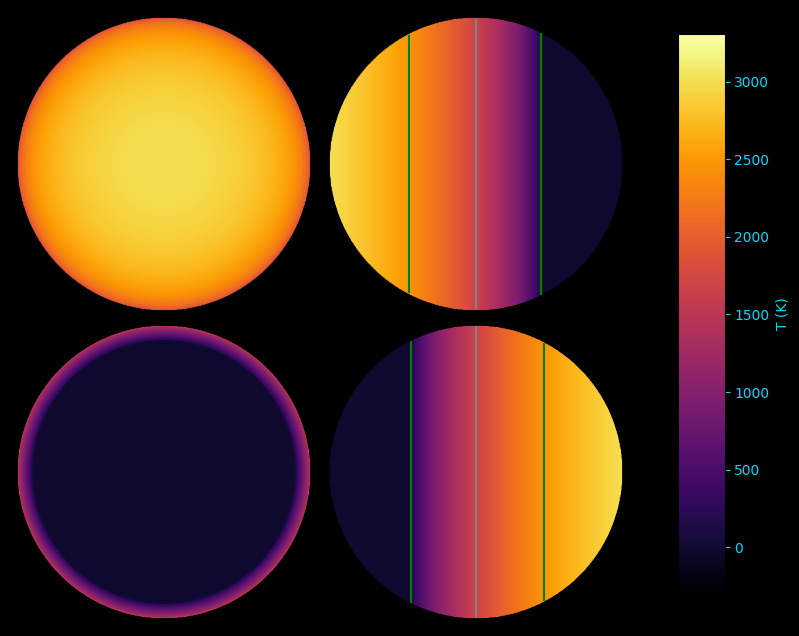

In [15]:
ax=plot_quad_insolmap(K2_141b, insolation_model="kopal", terminator=True, show_penumbra="both", unit="temperature")

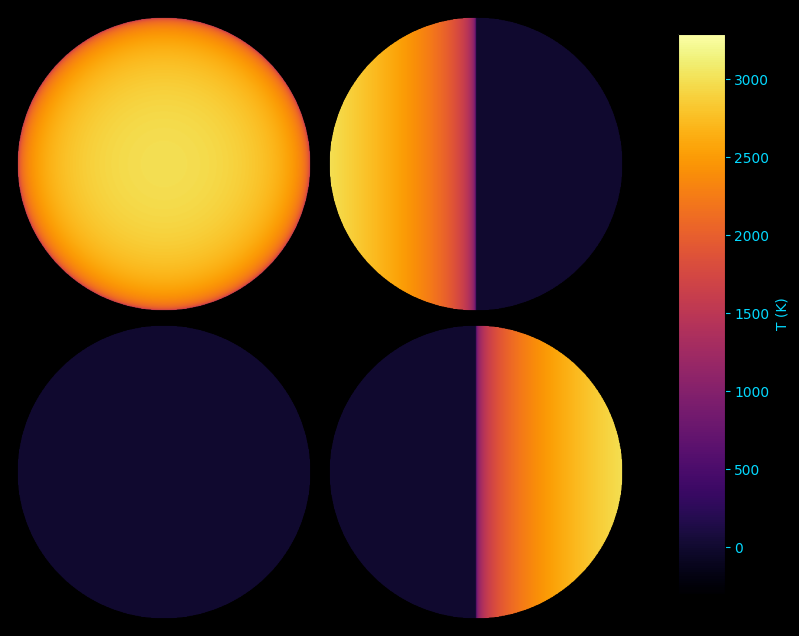

In [16]:
ax=plot_quad_insolmap(K2_141b, insolation_model="naive", unit="temperature")

In [17]:
# from IPython.display import Image
#
# animation_insolmap(K2_141b, insolation_model="kopal", terminator=True, unit="temperature", filename="tempmap_kopal")
# animation_insolmap(K2_141b, insolation_model="naive", terminator=False, unit="temperature", filename="tempmap_naive")
# animation_insolmap(K2_141b, insolation_model="kopal", terminator=True, unit="flux", filename="fluxmap_kopal")
# animation_insolmap(K2_141b, insolation_model="naive", terminator=False, unit="flux", filename="fluxmap_naive")

In [18]:
#Image(filename="tempmap_kopal.gif")

In [19]:
#Image(filename="tempmap_naive.gif")

In [20]:
#Image(filename="fluxmap_kopal.gif")

In [21]:
#Image(filename="fluxmap_naive.gif")